In [4]:
import pandas as pd
import json
import matplotlib.pyplot as plt

In [2]:
archivos_json = ['Streaming_History_Audio_2024.json', 'Streaming_History_Audio_2025.json', 'Streaming_History_Audio_2026.json']
lista_df = []

for archivo in archivos_json:
    with open(archivo, 'r', encoding='utf-8') as f:
        data = json.load(f)
        df_temporal = pd.DataFrame(data)
        lista_df.append(df_temporal)

df = pd.concat(lista_df, ignore_index=True)
df['ts'] = pd.to_datetime(df['ts'])

In [3]:
df.columns

Index(['ts', 'platform', 'ms_played', 'conn_country', 'ip_addr',
       'master_metadata_track_name', 'master_metadata_album_artist_name',
       'master_metadata_album_album_name', 'spotify_track_uri', 'episode_name',
       'episode_show_name', 'spotify_episode_uri', 'audiobook_title',
       'audiobook_uri', 'audiobook_chapter_uri', 'audiobook_chapter_title',
       'reason_start', 'reason_end', 'shuffle', 'skipped', 'offline',
       'offline_timestamp', 'incognito_mode'],
      dtype='object')

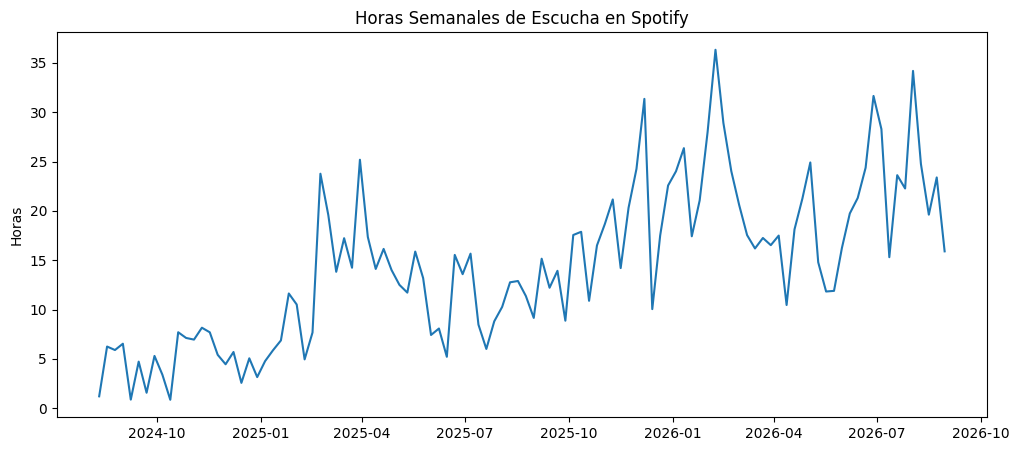

In [6]:
df['ts'] = pd.to_datetime(df['ts'])
df_ts = df[['ts', 'ms_played']].copy()
df_ts.set_index('ts', inplace=True)

# Resampleo semanal ('W') sumando milisegundos y convirtiendo a horas
serie_semanal = df_ts['ms_played'].resample('W').sum() / (1000 * 60 * 60)
serie_semanal = serie_semanal.dropna()

plt.figure(figsize=(12, 5))
plt.plot(serie_semanal)
plt.title('Horas Semanales de Escucha en Spotify')
plt.ylabel('Horas')
plt.show()

In [7]:
print(len(serie_semanal))

108
